# Data wrangling com Python

Este notebook desenvolve um fluxo completo de limpeza e preparação de dados. O ponto de partida é uma base de clientes de telecomunicações criada de forma reprodutível e contaminada propositalmente com problemas semelhantes aos encontrados em bases reais: duplicidades, valores ausentes explícitos e implícitos, tipos incorretos, categorias inconsistentes, datas inválidas, valores impossíveis e outliers.

O objetivo não é apenas executar comandos do `pandas`. Cada etapa apresenta a justificativa estatística da técnica, o código correspondente e a interpretação do resultado. Ao final, serão produzidos conjuntos numéricos sem valores ausentes, separados em treino e teste e prontos para algoritmos de machine learning.

## Visão geral do processo

Data wrangling é o processo de transformar dados brutos em uma representação confiável para análise e modelagem. A qualidade da etapa final depende da ordem das operações. Primeiro são corrigidos problemas estruturais e semânticos. Em seguida, a base é dividida em treino e teste. Somente depois são calculadas medianas, modas, limites de outliers, categorias do one-hot encoding e parâmetros de padronização.

Essa ordem evita **vazamento de dados**. Quando uma estatística é calculada usando também o conjunto de teste, informações que deveriam permanecer desconhecidas durante o treinamento passam a influenciar a preparação dos dados. A avaliação do modelo pode, então, parecer melhor do que realmente seria em dados novos.

O fluxo adotado será:

1. criação e inspeção da base bruta;
2. padronização estrutural e remoção de duplicidades;
3. conversão de tipos e validação de domínios;
4. normalização de categorias e binarização;
5. engenharia de atributos com datas;
6. separação entre treino e teste;
7. detecção e tratamento de outliers com z-score;
8. imputação de valores ausentes;
9. codificação one-hot das variáveis categóricas;
10. padronização z-score das variáveis numéricas;
11. validação e exportação das planilhas finais.

## Variáveis da base

A base representa clientes de uma empresa de telecomunicações. A variável-alvo é `churn`, que indica se o cliente cancelou o serviço. O problema de machine learning associado seria uma classificação binária.

| Variável | Tipo conceitual | Significado |
|---|---|---|
| ID Cliente | identificador | código único do cliente |
| Idade | numérica discreta | idade em anos |
| Renda Mensal | numérica contínua | renda mensal em reais |
| Gasto Médio Mensal | numérica contínua | valor médio mensal pago pelo serviço |
| Tempo de Cliente | numérica discreta | permanência em meses |
| Chamados Suporte | numérica discreta | quantidade recente de chamados |
| Avaliação Satisfação | ordinal | avaliação de 1 a 5 |
| Data de Cadastro | temporal | data de entrada do cliente |
| Região | categórica nominal | região brasileira |
| Plano | categórica ordinal | plano contratado |
| Forma de Pagamento | categórica nominal | meio de pagamento |
| Possui Dependentes | categórica binária | resposta sim ou não |
| Recebe Newsletter | categórica binária | resposta sim ou não |
| Churn | alvo binário | ocorrência de cancelamento |

O identificador será preservado na base limpa para rastreabilidade, mas excluído da matriz de modelagem. Um número usado apenas para identificar registros não representa uma característica do fenômeno e pode induzir o algoritmo a aprender relações artificiais.

In [ ]:
import re
import unicodedata
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    def display(objeto):
        print(objeto)
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")
sns.set_theme(style="whitegrid")

SEMENTE = 42
DATA_REFERENCIA = pd.Timestamp("2026-08-28")
rng = np.random.default_rng(SEMENTE)

## 1. Construção de uma base propositalmente problemática

Uma base didática de limpeza precisa conter problemas que tenham significado. Por isso, os dados são gerados com relações plausíveis. O cancelamento é mais provável entre clientes com muitos chamados, baixa satisfação, menor tempo de permanência e determinados planos. Depois da geração, são inseridos erros controlados.

A semente aleatória fixa garante reprodutibilidade. Sempre que o notebook for executado, a mesma base será produzida e os resultados poderão ser comparados entre diferentes execuções.

In [ ]:
def formatar_moeda_br(valor):
    texto = f"{valor:,.2f}"
    texto = texto.replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {texto}"


n = 160
idade = np.clip(rng.normal(39, 12, n).round(), 18, 75)
renda = np.clip(rng.lognormal(mean=np.log(4500), sigma=0.45, size=n), 1500, 16000)
plano = rng.choice(["Básico", "Intermediário", "Premium"], n, p=[0.43, 0.37, 0.20])
tempo_cliente = rng.integers(1, 97, n)
chamados = rng.poisson(2.1, n)
satisfacao = rng.choice([1, 2, 3, 4, 5], n, p=[0.08, 0.14, 0.28, 0.30, 0.20])
gasto_base = np.select(
    [plano == "Básico", plano == "Intermediário", plano == "Premium"],
    [89.90, 149.90, 239.90]
)
gasto = np.clip(gasto_base + rng.normal(0, 18, n), 45, None)
regiao = rng.choice(["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"], n,
                    p=[0.45, 0.17, 0.20, 0.10, 0.08])
pagamento = rng.choice(
    ["Cartão de crédito", "Boleto", "Pix", "Débito automático"],
    n, p=[0.38, 0.22, 0.24, 0.16]
)
dependentes = rng.choice(["Sim", "Não"], n, p=[0.42, 0.58])
newsletter = rng.choice(["Sim", "Não"], n, p=[0.55, 0.45])

logito = (
    -1.65
    + 0.55 * (chamados >= 4)
    + 0.85 * (satisfacao <= 2)
    + 0.55 * (tempo_cliente <= 12)
    + 0.35 * (plano == "Básico")
    - 0.40 * (newsletter == "Sim")
)
probabilidade_churn = 1 / (1 + np.exp(-logito))
churn = np.where(rng.random(n) < probabilidade_churn, "Sim", "Não")

datas = [DATA_REFERENCIA - pd.DateOffset(months=int(m)) - pd.Timedelta(days=int(rng.integers(0, 28)))
         for m in tempo_cliente]
formatos = ["%d/%m/%Y", "%Y-%m-%d", "%d-%m-%Y"]
datas_texto = [data.strftime(formatos[i % len(formatos)]) for i, data in enumerate(datas)]

df_bruto = pd.DataFrame({
    "ID Cliente": np.arange(1001, 1001 + n),
    "Idade": idade,
    "Renda Mensal": [formatar_moeda_br(v) for v in renda],
    "Gasto Médio Mensal": gasto.round(2),
    "Tempo de Cliente (meses)": tempo_cliente,
    "Chamados Suporte": chamados,
    "Avaliação Satisfação": satisfacao,
    "Data de Cadastro": datas_texto,
    "Região": regiao,
    "Plano": plano,
    "Forma de Pagamento": pagamento,
    "Possui Dependentes": dependentes,
    "Recebe Newsletter": newsletter,
    "Churn": churn,
})

# Inserção controlada de problemas de qualidade.
df_bruto.loc[[5, 44], "Renda Mensal"] = None
df_bruto.loc[73, "Renda Mensal"] = "não informado"
df_bruto.loc[120, "Renda Mensal"] = formatar_moeda_br(120000)
df_bruto.loc[12, "Gasto Médio Mensal"] = "R$ 349,90"
df_bruto.loc[18, "Gasto Médio Mensal"] = None
df_bruto.loc[65, "Gasto Médio Mensal"] = -50
df_bruto.loc[130, "Gasto Médio Mensal"] = 25000
df_bruto.loc[7, "Idade"] = "vinte e nove"
df_bruto.loc[31, "Idade"] = None
df_bruto.loc[92, "Idade"] = 130
df_bruto.loc[14, "Tempo de Cliente (meses)"] = -6
df_bruto.loc[51, "Tempo de Cliente (meses)"] = None
df_bruto.loc[22, "Chamados Suporte"] = -2
df_bruto.loc[70, "Chamados Suporte"] = None
df_bruto.loc[110, "Chamados Suporte"] = 35
df_bruto.loc[39, "Avaliação Satisfação"] = 8
df_bruto.loc[84, "Avaliação Satisfação"] = None
df_bruto.loc[20, "Data de Cadastro"] = "31/02/2024"
df_bruto.loc[90, "Data de Cadastro"] = None

df_bruto.loc[[3, 25], "Região"] = [" sudeste ", "SUDESTE"]
df_bruto.loc[47, "Região"] = "centro oeste"
df_bruto.loc[74, "Região"] = None
df_bruto.loc[[8, 36], "Plano"] = ["basico", " PREMIUM "]
df_bruto.loc[61, "Plano"] = None
df_bruto.loc[[10, 58], "Forma de Pagamento"] = ["cartao de credito", "PIX "]
df_bruto.loc[82, "Forma de Pagamento"] = None
df_bruto.loc[[15, 48], "Possui Dependentes"] = ["SIM ", "nao"]
df_bruto.loc[95, "Possui Dependentes"] = None
df_bruto.loc[[17, 52], "Recebe Newsletter"] = ["sim", "NÃO "]
df_bruto.loc[97, "Recebe Newsletter"] = None
df_bruto.loc[[11, 54], "Churn"] = ["sim ", "NÃO"]
df_bruto.loc[101, "Churn"] = "cancelou"
df_bruto.loc[140, "Churn"] = None

# Três registros são duplicados integralmente e a ordem é embaralhada.
duplicados = df_bruto.iloc[[4, 27, 88]].copy()
df_bruto = pd.concat([df_bruto, duplicados], ignore_index=True)
df_bruto = df_bruto.sample(frac=1, random_state=SEMENTE).reset_index(drop=True)

print(f"Dimensão inicial: {df_bruto.shape[0]} linhas e {df_bruto.shape[1]} colunas")
display(df_bruto.head(8))

Dimensão inicial: 163 linhas e 14 colunas


,ID Cliente,Idade,Renda Mensal,Gasto Médio Mensal,Tempo de Cliente (meses),Chamados Suporte,Avaliação Satisfação,Data de Cadastro,Região,Plano,Forma de Pagamento,Possui Dependentes,Recebe Newsletter,Churn
0,1136,27.000,"R$ 4.872,02",255.680,48.000,2.000,3.000,13/08/2022,Sul,Premium,Cartão de crédito,Não,Sim,Não
1,1116,33.000,"R$ 5.353,27",137.750,42.000,2.000,2.000,2023-02-01,Nordeste,Intermediário,Pix,Não,Sim,Não
2,1132,22.000,"R$ 4.819,79",87.670,48.000,2.000,1.000,16-08-2022,Sudeste,Básico,Boleto,Sim,Sim,Não
3,1056,31.000,"R$ 7.066,17",225.560,80.000,1.000,4.000,2019-12-03,Centro-Oeste,Premium,Pix,Não,Não,Não
4,1096,22.000,"R$ 6.384,54",232.800,81.000,4.000,5.000,18-11-2019,Nordeste,Premium,Cartão de crédito,None,Não,Não
5,1030,44.000,"R$ 9.459,27",103.020,31.000,2.000,4.000,16-01-2024,Sudeste,Básico,Cartão de crédito,Não,Sim,Não
6,1157,41.000,"R$ 4.636,79",156.250,85.000,3.000,1.000,27/07/2019,Sudeste,Intermediário,Débito automático,Não,Sim,Sim
7,1052,47.000,"R$ 2.477,38",146.810,NaN,0.000,3.000,17/08/2020,Nordeste,Intermediário,Boleto,Sim,Sim,Não


**Interpretação do resultado.** A tabela contém 163 linhas porque três registros foram duplicados depois da criação dos 160 clientes originais. Algumas falhas são visualmente identificáveis, como espaços adicionais e grafias distintas. Outras permanecem ocultas: o texto `não informado` não é contabilizado pelo `pandas` como valor ausente, valores monetários estão armazenados como texto e números impossíveis ainda parecem numericamente válidos.

## 2. Auditoria inicial da qualidade

A inspeção inicial deve separar quatro dimensões de qualidade. A dimensão **estrutural** verifica formato, nomes de colunas, tipos e duplicidades. A dimensão **sintática** examina se o valor respeita o formato esperado. A dimensão **semântica** verifica se o valor faz sentido no domínio, como idade igual a 130 anos ou satisfação igual a 8 em uma escala de 1 a 5. A dimensão **estatística** procura valores extremos, distribuições inadequadas e possíveis relações anômalas.

O método `info()` é importante, mas insuficiente. Uma coluna de renda armazenada como `object` pode reunir moedas, números e marcadores textuais de ausência. Por isso, a auditoria combina tipos, percentual de ausências, cardinalidade, duplicidades e amostras de valores.

In [ ]:
def auditar_dataframe(df):
    auditoria = pd.DataFrame({
        "tipo_pandas": df.dtypes.astype(str),
        "ausentes": df.isna().sum(),
        "ausentes_pct": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(dropna=True),
    })
    return auditoria


print(f"Duplicidades exatas: {df_bruto.duplicated().sum()}")
display(auditar_dataframe(df_bruto))

print("Amostra de valores presentes em colunas categóricas:")
for coluna in ["Região", "Plano", "Forma de Pagamento", "Possui Dependentes",
               "Recebe Newsletter", "Churn"]:
    print(f"{coluna}: {df_bruto[coluna].dropna().unique()}")

Duplicidades exatas: 3


,tipo_pandas,ausentes,ausentes_pct,valores_unicos
ID Cliente,int64,0,0.000,160
Idade,object,1,0.610,43
Renda Mensal,object,2,1.230,158
Gasto Médio Mensal,object,1,0.610,158
Tempo de Cliente (meses),float64,1,0.610,83
Chamados Suporte,float64,1,0.610,9
Avaliação Satisfação,float64,1,0.610,6
Data de Cadastro,object,1,0.610,157
Região,object,1,0.610,8
Plano,object,1,0.610,5


Amostra de valores presentes em colunas categóricas:
Região: ['Sul' 'Nordeste' 'Sudeste' 'Centro-Oeste' 'Norte' 'SUDESTE'
 'centro oeste' ' sudeste ']
Plano: ['Premium' 'Intermediário' 'Básico' ' PREMIUM ' 'basico']
Forma de Pagamento: ['Cartão de crédito' 'Pix' 'Boleto' 'Débito automático'
 'cartao de credito' 'PIX ']
Possui Dependentes: ['Não' 'Sim' 'SIM ' 'nao']
Recebe Newsletter: ['Sim' 'Não' 'sim' 'NÃO ']
Churn: ['Não' 'Sim' 'cancelou' 'sim ' 'NÃO']


**Interpretação do resultado.** A auditoria confirma as três duplicidades exatas. `Idade`, `Renda Mensal` e `Gasto Médio Mensal` aparecem como `object`, embora representem variáveis numéricas. Isso ocorre porque basta a presença de textos em uma coluna para que o `pandas` abandone um tipo exclusivamente numérico. A listagem das categorias também mostra que diferenças de caixa, acentuação e espaços criaram representações distintas para o mesmo conceito.

## 3. Padronização estrutural e remoção de duplicidades

Nomes de colunas consistentes reduzem erros de programação e facilitam a seleção de variáveis. Será adotado o padrão `snake_case`, com letras minúsculas, ausência de acentos e palavras separadas por sublinhado.

A remoção de duplicidades deve ocorrer antes do cálculo de frequências ou estatísticas. Registros repetidos recebem peso indevido em médias, medianas, distribuições e treinamento. Entretanto, não se deve remover automaticamente registros apenas porque compartilham alguns atributos. Nesta etapa são removidas somente duplicidades integrais, nas quais todas as colunas são iguais.

In [ ]:
def padronizar_nome_coluna(nome):
    nome = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode("ascii")
    nome = nome.lower().strip()
    nome = re.sub(r"[^a-z0-9]+", "_", nome)
    return nome.strip("_")


df_limpo = df_bruto.copy()
df_limpo.columns = [padronizar_nome_coluna(coluna) for coluna in df_limpo.columns]

colunas_textuais = df_limpo.select_dtypes(include="object").columns
for coluna in colunas_textuais:
    df_limpo[coluna] = df_limpo[coluna].map(
        lambda valor: valor.strip() if isinstance(valor, str) else valor
    )

linhas_antes = len(df_limpo)
df_limpo = df_limpo.drop_duplicates().copy()
linhas_removidas = linhas_antes - len(df_limpo)

print("Nomes padronizados:")
print(df_limpo.columns.tolist())
print(f"Duplicidades removidas: {linhas_removidas}")
print(f"Linhas restantes: {len(df_limpo)}")

Nomes padronizados:
['id_cliente', 'idade', 'renda_mensal', 'gasto_medio_mensal', 'tempo_de_cliente_meses', 'chamados_suporte', 'avaliacao_satisfacao', 'data_de_cadastro', 'regiao', 'plano', 'forma_de_pagamento', 'possui_dependentes', 'recebe_newsletter', 'churn']
Duplicidades removidas: 3
Linhas restantes: 160


**Interpretação do resultado.** Os nomes passam a ser adequados para acesso programático, e exatamente três linhas são removidas. A base retorna aos 160 clientes originais. A remoção de espaços nas extremidades corrige parte das inconsistências, mas ainda não unifica diferenças como `SUDESTE`, `sudeste` e `Sudeste`; essa tarefa será realizada na normalização semântica das categorias.

## 4. Conversão de tipos numéricos e temporais

Um tipo de armazenamento não é apenas uma propriedade técnica. Ele determina quais operações são possíveis e como os valores são interpretados. Uma renda armazenada como texto não pode ser usada corretamente em médias, correlações ou modelos.

A conversão deve tolerar formatos conhecidos e transformar valores incompreensíveis em `NaN`. O uso de `errors="coerce"` é preferível a inventar um valor, pois preserva a informação de que houve falha de conversão. Valores monetários brasileiros exigem a remoção do símbolo, dos separadores de milhar e a troca da vírgula decimal por ponto. Datas são convertidas para `datetime`, permitindo validação cronológica e criação de atributos temporais.

In [ ]:
def converter_numero_br(valor):
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return float(valor)

    texto = str(valor).strip().replace("R$", "").replace(" ", "")
    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")
    return pd.to_numeric(texto, errors="coerce")


conversoes_numericas = [
    "idade", "renda_mensal", "gasto_medio_mensal", "tempo_de_cliente_meses",
    "chamados_suporte", "avaliacao_satisfacao"
]

for coluna in conversoes_numericas:
    df_limpo[coluna] = df_limpo[coluna].map(converter_numero_br)

df_limpo["data_de_cadastro"] = pd.to_datetime(
    df_limpo["data_de_cadastro"], format="mixed", dayfirst=True, errors="coerce"
)

display(df_limpo[conversoes_numericas + ["data_de_cadastro"]].dtypes.to_frame("tipo_corrigido"))
display(df_limpo[conversoes_numericas + ["data_de_cadastro"]].isna().sum().to_frame("ausentes_apos_conversao"))

,tipo_corrigido
idade,float64
renda_mensal,float64
gasto_medio_mensal,float64
tempo_de_cliente_meses,float64
chamados_suporte,float64
avaliacao_satisfacao,float64
data_de_cadastro,datetime64[ns]


,ausentes_apos_conversao
idade,2
renda_mensal,3
gasto_medio_mensal,1
tempo_de_cliente_meses,1
chamados_suporte,1
avaliacao_satisfacao,1
data_de_cadastro,2


**Interpretação do resultado.** As variáveis numéricas passam a usar tipos numéricos, e a data passa a usar `datetime64`. O texto `vinte e nove`, o marcador `não informado` e a data impossível `31/02/2024` são convertidos em ausência. Essa conversão não resolve o problema por completo; apenas torna as falhas explícitas e tratáveis nas etapas seguintes.

## 5. Validação de domínio

A conversão de tipo verifica se um valor pode ser representado como número ou data, mas não garante validade semântica. Uma idade igual a 130 é numericamente válida, embora seja incompatível com o domínio adotado. O mesmo ocorre com quantidade negativa de chamados, permanência negativa ou satisfação fora da escala estabelecida.

Os limites devem ser definidos com conhecimento do problema, e não apenas pela distribuição observada. Valores semanticamente impossíveis são transformados em ausências para posterior imputação. Esse procedimento é diferente do tratamento de outliers: um outlier pode ser raro e ainda assim legítimo; um valor fora do domínio viola uma regra do sistema.

In [ ]:
regras_validade = {
    "idade": df_limpo["idade"].between(18, 90),
    "renda_mensal": df_limpo["renda_mensal"] > 0,
    "gasto_medio_mensal": df_limpo["gasto_medio_mensal"] >= 0,
    "tempo_de_cliente_meses": df_limpo["tempo_de_cliente_meses"] >= 0,
    "chamados_suporte": df_limpo["chamados_suporte"] >= 0,
    "avaliacao_satisfacao": df_limpo["avaliacao_satisfacao"].between(1, 5),
}

relatorio_invalidos = []
for coluna, mascara_valida in regras_validade.items():
    mascara_invalida = df_limpo[coluna].notna() & ~mascara_valida
    relatorio_invalidos.append({
        "coluna": coluna,
        "valores_invalidos": int(mascara_invalida.sum())
    })
    df_limpo.loc[mascara_invalida, coluna] = np.nan

datas_futuras = df_limpo["data_de_cadastro"].notna() & (df_limpo["data_de_cadastro"] > DATA_REFERENCIA)
df_limpo.loc[datas_futuras, "data_de_cadastro"] = pd.NaT

display(pd.DataFrame(relatorio_invalidos))

,coluna,valores_invalidos
0,idade,1
1,renda_mensal,0
2,gasto_medio_mensal,1
3,tempo_de_cliente_meses,1
4,chamados_suporte,1
5,avaliacao_satisfacao,1


**Interpretação do resultado.** A idade 130, o gasto negativo, o tempo de permanência negativo, a quantidade negativa de chamados e a satisfação 8 são identificados pelas regras de domínio e convertidos em ausência. Os valores muito altos de renda, gasto e chamados não são removidos aqui, pois permanecem possíveis. Eles serão avaliados estatisticamente como candidatos a outliers.

## 6. Normalização categórica e binarização

Variáveis categóricas exigem equivalência semântica. `PIX`, `Pix` e `pix` devem representar a mesma categoria. O procedimento adotado cria uma forma auxiliar sem acentos, sem espaços adicionais e em letras minúsculas, e então aplica um dicionário explícito para recuperar os rótulos canônicos.

Categorias não reconhecidas tornam-se ausentes. Essa decisão é mais segura do que aceitar silenciosamente uma nova grafia como categoria legítima. Para variáveis binárias, `Sim` e `Não` são transformados em 1 e 0. A binarização não implica ordem ou distância artificial, pois há apenas dois estados. A variável-alvo recebe o mesmo tratamento, mas nunca será imputada: sem o rótulo verdadeiro, a observação não pode participar de um treinamento supervisionado.

In [ ]:
def normalizar_rotulo(valor):
    if pd.isna(valor):
        return None
    texto = unicodedata.normalize("NFKD", str(valor)).encode("ascii", "ignore").decode("ascii")
    texto = re.sub(r"\s+", " ", texto.strip().lower())
    return texto


def mapear_categoria(serie, mapa):
    return serie.map(lambda valor: mapa.get(normalizar_rotulo(valor), np.nan))


mapas_categorias = {
    "regiao": {
        "sudeste": "Sudeste", "sul": "Sul", "nordeste": "Nordeste",
        "centro-oeste": "Centro-Oeste", "centro oeste": "Centro-Oeste", "norte": "Norte"
    },
    "plano": {
        "basico": "Básico", "intermediario": "Intermediário", "premium": "Premium"
    },
    "forma_de_pagamento": {
        "cartao de credito": "Cartão de crédito", "boleto": "Boleto",
        "pix": "Pix", "debito automatico": "Débito automático"
    },
}

for coluna, mapa in mapas_categorias.items():
    df_limpo[coluna] = mapear_categoria(df_limpo[coluna], mapa)

mapa_binario = {"sim": 1.0, "nao": 0.0}
for coluna in ["possui_dependentes", "recebe_newsletter", "churn"]:
    df_limpo[coluna] = mapear_categoria(df_limpo[coluna], mapa_binario)

for coluna in ["regiao", "plano", "forma_de_pagamento", "possui_dependentes",
               "recebe_newsletter", "churn"]:
    print(f"{coluna}: {sorted(df_limpo[coluna].dropna().unique().tolist())}")

regiao: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']
plano: ['Básico', 'Intermediário', 'Premium']
forma_de_pagamento: ['Boleto', 'Cartão de crédito', 'Débito automático', 'Pix']
possui_dependentes: [0.0, 1.0]
recebe_newsletter: [0.0, 1.0]
churn: [0.0, 1.0]


**Interpretação do resultado.** Cada variável categórica passa a possuir apenas os níveis previstos no domínio. As duas variáveis explicativas binárias e o alvo passam a conter somente 0 e 1, além de eventuais ausências. O valor `cancelou`, inserido propositalmente na variável-alvo, não pertence ao vocabulário aceito e é convertido em ausência.

## 7. Tratamento do alvo e engenharia de atributos temporais

A imputação da variável-alvo produziria rótulos inventados e contaminaria a aprendizagem supervisionada. Por isso, registros sem `churn` válido são removidos. Essa exclusão deve ser registrada, pois pode introduzir viés se a ausência do alvo estiver associada a algum grupo específico.

Datas raramente são utilizadas diretamente por algoritmos tradicionais. Elas são transformadas em características numéricas com significado, como dias de relacionamento, ano e mês de cadastro. O cálculo utiliza uma data de referência fixa para garantir reprodutibilidade. A data original permanece na base limpa, mas será retirada da matriz final.

In [ ]:
linhas_sem_alvo = int(df_limpo["churn"].isna().sum())
df_limpo = df_limpo.dropna(subset=["churn"]).copy()
df_limpo["churn"] = df_limpo["churn"].astype(int)

df_limpo["dias_como_cliente"] = (DATA_REFERENCIA - df_limpo["data_de_cadastro"]).dt.days
df_limpo.loc[df_limpo["dias_como_cliente"] < 0, "dias_como_cliente"] = np.nan
df_limpo["ano_cadastro"] = df_limpo["data_de_cadastro"].dt.year
df_limpo["mes_cadastro"] = df_limpo["data_de_cadastro"].dt.month

print(f"Linhas removidas por ausência ou invalidade do alvo: {linhas_sem_alvo}")
print(f"Dimensão da base limpa antes do pré-processamento: {df_limpo.shape}")
display(df_limpo.head())
display(df_limpo.isna().sum().sort_values(ascending=False).to_frame("ausentes"))

Linhas removidas por ausência ou invalidade do alvo: 2
Dimensão da base limpa antes do pré-processamento: (158, 17)


,id_cliente,idade,renda_mensal,gasto_medio_mensal,tempo_de_cliente_meses,chamados_suporte,avaliacao_satisfacao,data_de_cadastro,regiao,plano,forma_de_pagamento,possui_dependentes,recebe_newsletter,churn,dias_como_cliente,ano_cadastro,mes_cadastro
0,1136,27.000,"4,872.020",255.680,48.000,2.000,3.000,2022-08-13,Sul,Premium,Cartão de crédito,0.000,1.000,0,"1,476.000","2,022.000",8.000
1,1116,33.000,"5,353.270",137.750,42.000,2.000,2.000,2023-02-01,Nordeste,Intermediário,Pix,0.000,1.000,0,"1,304.000","2,023.000",2.000
2,1132,22.000,"4,819.790",87.670,48.000,2.000,1.000,2022-08-16,Sudeste,Básico,Boleto,1.000,1.000,0,"1,473.000","2,022.000",8.000
3,1056,31.000,"7,066.170",225.560,80.000,1.000,4.000,2019-12-03,Centro-Oeste,Premium,Pix,0.000,0.000,0,"2,460.000","2,019.000",12.000
4,1096,22.000,"6,384.540",232.800,81.000,4.000,5.000,2019-11-18,Nordeste,Premium,Cartão de crédito,NaN,0.000,0,"2,475.000","2,019.000",11.000


,ausentes
idade,3
renda_mensal,3
dias_como_cliente,2
gasto_medio_mensal,2
tempo_de_cliente_meses,2
chamados_suporte,2
avaliacao_satisfacao,2
data_de_cadastro,2
ano_cadastro,2
mes_cadastro,2


**Interpretação do resultado.** Duas linhas são removidas porque não possuem rótulo válido: uma continha `cancelou` e outra estava vazia. A base de trabalho passa a ter 158 observações. As ausências restantes pertencem às variáveis explicativas e serão tratadas sem descartar linhas. A base `df_limpo` preserva categorias legíveis e é adequada para análise exploratória, mas ainda não está pronta para machine learning.

## 8. Separação entre treino e teste

Operações determinísticas, como correção de tipos, padronização de rótulos e aplicação de regras fixas de domínio, podem ser realizadas antes da divisão. Operações que aprendem parâmetros a partir dos dados devem ser ajustadas somente com o conjunto de treino.

A divisão estratificada preserva aproximadamente a proporção de cancelamentos nos dois conjuntos. O teste representa dados desconhecidos e será usado apenas para receber transformações aprendidas no treino. O identificador e a data original são excluídos das variáveis explicativas.

In [ ]:
X = df_limpo.drop(columns=["churn", "id_cliente", "data_de_cadastro"])
y = df_limpo["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)

print(f"Treino: {X_train.shape[0]} linhas")
print(f"Teste: {X_test.shape[0]} linhas")
print("Proporção de churn:")
display(pd.DataFrame({
    "base_completa": y.value_counts(normalize=True).sort_index(),
    "treino": y_train.value_counts(normalize=True).sort_index(),
    "teste": y_test.value_counts(normalize=True).sort_index(),
}).round(3))

Treino: 126 linhas
Teste: 32 linhas
Proporção de churn:


,base_completa,treino,teste
churn,,,
0,0.759,0.762,0.750
1,0.241,0.238,0.250


**Interpretação do resultado.** O conjunto de treino recebe aproximadamente 80% das observações, e o teste recebe os 20% restantes. As proporções de `churn = 0` e `churn = 1` permanecem próximas entre os conjuntos, reduzindo o risco de uma avaliação distorcida por uma divisão acidentalmente desequilibrada.

## 9. Outliers e z-score

O z-score mede quantos desvios-padrão um valor está afastado da média:

$$z_i = \frac{x_i - \mu}{\sigma}$$

Em distribuições aproximadamente simétricas, valores com $|z| > 3$ são candidatos usuais a outliers. Esse limite não constitui uma lei universal. O z-score é sensível à própria média e ao desvio-padrão, e pode ser inadequado para distribuições muito assimétricas. Em outros contextos, podem ser preferíveis intervalo interquartil, MAD, transformação logarítmica ou modelos específicos de detecção de anomalias.

Aqui, o z-score será usado para obter limites a partir do treino. Os valores externos serão limitados ao intervalo de três desvios-padrão, técnica chamada *clipping* ou winsorização. A observação é preservada, mas sua influência extrema é reduzida. Os mesmos limites aprendidos no treino serão aplicados ao teste.

,coluna,media_treino,desvio_treino,limite_inferior,limite_superior,outliers_treino
0,renda_mensal,"5,989.130","10,604.980","-25,825.810","37,804.060",1
1,gasto_medio_mensal,346.510,"2,223.730","-6,324.690","7,017.700",1
2,chamados_suporte,2.420,3.240,-7.290,12.130,1


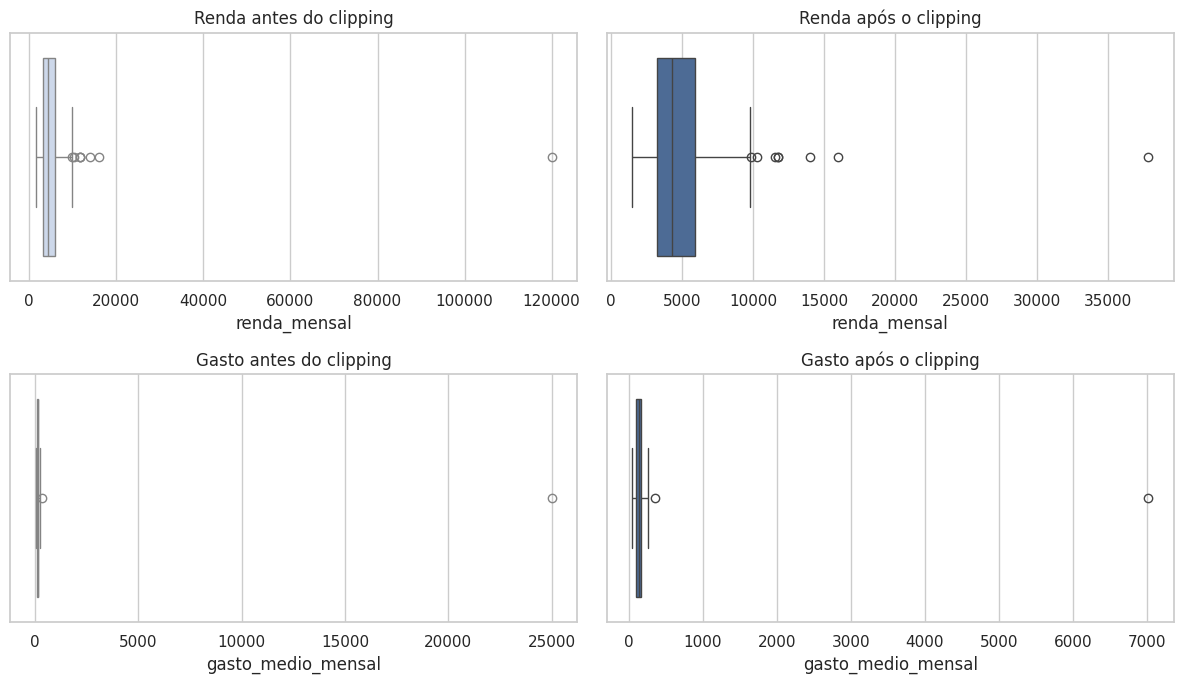

In [ ]:
colunas_outliers = ["renda_mensal", "gasto_medio_mensal", "chamados_suporte"]

def aprender_limites_z(df, colunas, limite_z=3.0):
    limites = {}
    relatorio = []
    for coluna in colunas:
        media = df[coluna].mean(skipna=True)
        desvio = df[coluna].std(skipna=True, ddof=0)
        inferior = media - limite_z * desvio
        superior = media + limite_z * desvio
        quantidade = int(((df[coluna] < inferior) | (df[coluna] > superior)).sum())
        limites[coluna] = (inferior, superior)
        relatorio.append({
            "coluna": coluna,
            "media_treino": media,
            "desvio_treino": desvio,
            "limite_inferior": inferior,
            "limite_superior": superior,
            "outliers_treino": quantidade,
        })
    return limites, pd.DataFrame(relatorio)


def aplicar_clipping(df, limites):
    resultado = df.copy()
    for coluna, (inferior, superior) in limites.items():
        resultado[coluna] = resultado[coluna].clip(lower=inferior, upper=superior)
    return resultado


limites_z, relatorio_z = aprender_limites_z(X_train, colunas_outliers, limite_z=3.0)
X_train_tratado = aplicar_clipping(X_train, limites_z)
X_test_tratado = aplicar_clipping(X_test, limites_z)

display(relatorio_z.round(2))

fig, eixos = plt.subplots(2, 2, figsize=(12, 7))
sns.boxplot(x=X_train["renda_mensal"], ax=eixos[0, 0], color="#c8d7ef")
eixos[0, 0].set_title("Renda antes do clipping")
sns.boxplot(x=X_train_tratado["renda_mensal"], ax=eixos[0, 1], color="#4169a1")
eixos[0, 1].set_title("Renda após o clipping")
sns.boxplot(x=X_train["gasto_medio_mensal"], ax=eixos[1, 0], color="#c8d7ef")
eixos[1, 0].set_title("Gasto antes do clipping")
sns.boxplot(x=X_train_tratado["gasto_medio_mensal"], ax=eixos[1, 1], color="#4169a1")
eixos[1, 1].set_title("Gasto após o clipping")
plt.tight_layout()
plt.show()

**Interpretação do resultado.** O relatório informa a média, o desvio-padrão e os limites calculados exclusivamente no treino. Os boxplots permitem observar a redução da escala produzida pelos valores extremos. O clipping não transforma toda a distribuição em normal e não elimina automaticamente observações. Ele apenas impede que valores muito distantes dominem etapas sensíveis à escala.

## 10. Imputação de valores ausentes

A ausência pode ser completamente aleatória, associada a variáveis observadas ou relacionada ao próprio valor que falta. Essas situações são conhecidas, respectivamente, como MCAR, MAR e MNAR. A técnica de imputação deve considerar o mecanismo de ausência e o objetivo da análise.

Para variáveis numéricas será utilizada a mediana, que é menos sensível a assimetria e outliers do que a média. Para variáveis categóricas e binárias será utilizada a moda. Essas escolhas fornecem uma base geral para ensino, mas não substituem análise do domínio. Em aplicações reais, também podem ser empregados indicadores de ausência, imputação por grupos, KNN ou modelos multivariados.

Os imputadores são ajustados no treino. O teste recebe exatamente as medianas e modas aprendidas no treino.

In [ ]:
colunas_numericas = [
    "idade", "renda_mensal", "gasto_medio_mensal", "tempo_de_cliente_meses",
    "chamados_suporte", "avaliacao_satisfacao", "dias_como_cliente",
    "ano_cadastro", "mes_cadastro"
]
colunas_binarias = ["possui_dependentes", "recebe_newsletter"]
colunas_categoricas = ["regiao", "plano", "forma_de_pagamento"]

imputador_numerico = SimpleImputer(strategy="median")
imputador_binario = SimpleImputer(strategy="most_frequent")
imputador_categorico = SimpleImputer(strategy="most_frequent")

X_train_imputado = X_train_tratado.copy()
X_test_imputado = X_test_tratado.copy()

X_train_imputado[colunas_numericas] = imputador_numerico.fit_transform(X_train_tratado[colunas_numericas])
X_test_imputado[colunas_numericas] = imputador_numerico.transform(X_test_tratado[colunas_numericas])

X_train_imputado[colunas_binarias] = imputador_binario.fit_transform(X_train_tratado[colunas_binarias])
X_test_imputado[colunas_binarias] = imputador_binario.transform(X_test_tratado[colunas_binarias])

X_train_imputado[colunas_categoricas] = imputador_categorico.fit_transform(X_train_tratado[colunas_categoricas])
X_test_imputado[colunas_categoricas] = imputador_categorico.transform(X_test_tratado[colunas_categoricas])

estatisticas_imputacao = pd.DataFrame({
    "coluna": colunas_numericas,
    "mediana_aprendida_no_treino": imputador_numerico.statistics_
})
display(estatisticas_imputacao.round(2))
print(f"Ausências no treino após imputação: {int(X_train_imputado.isna().sum().sum())}")
print(f"Ausências no teste após imputação: {int(X_test_imputado.isna().sum().sum())}")

,coluna,mediana_aprendida_no_treino
0,idade,39.000
1,renda_mensal,"4,301.240"
2,gasto_medio_mensal,136.890
3,tempo_de_cliente_meses,49.000
4,chamados_suporte,2.000
5,avaliacao_satisfacao,4.000
6,dias_como_cliente,"1,517.500"
7,ano_cadastro,"2,022.000"
8,mes_cadastro,6.000


Ausências no treino após imputação: 0
Ausências no teste após imputação: 0


**Interpretação do resultado.** A tabela apresenta as medianas efetivamente aprendidas no conjunto de treino. Após a transformação, treino e teste não possuem valores ausentes. A ausência de `NaN` não significa que a incerteza desapareceu; significa que ela foi tratada por uma regra explícita e reproduzível. As estatísticas armazenadas nos objetos de imputação devem ser reutilizadas quando novos dados forem processados.

## 11. One-hot encoding para categorias nominais

Algoritmos numéricos não interpretam diretamente rótulos como `Sudeste` ou `Premium`. Atribuir números inteiros arbitrários, como Sudeste = 1 e Sul = 2, criaria uma ordem e uma distância inexistentes. O one-hot encoding cria uma coluna indicadora para cada categoria.

O parâmetro `handle_unknown="ignore"` impede erro quando o teste ou dados futuros contêm uma categoria que não apareceu no treino. Nesse caso, todas as colunas daquele atributo recebem zero. O codificador é ajustado somente no treino para que o vocabulário de categorias não seja influenciado pelo conjunto de teste.

As variáveis `possui_dependentes` e `recebe_newsletter` já foram binarizadas como 0 e 1 e, portanto, não precisam de one-hot encoding.

In [ ]:
try:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float64)
except TypeError:
    # Compatibilidade com versões antigas do scikit-learn.
    codificador = OneHotEncoder(handle_unknown="ignore", sparse=False, dtype=np.float64)

treino_categorias = codificador.fit_transform(X_train_imputado[colunas_categoricas])
teste_categorias = codificador.transform(X_test_imputado[colunas_categoricas])
nomes_categorias = codificador.get_feature_names_out(colunas_categoricas)

df_treino_categorias = pd.DataFrame(
    treino_categorias, columns=nomes_categorias, index=X_train_imputado.index
)
df_teste_categorias = pd.DataFrame(
    teste_categorias, columns=nomes_categorias, index=X_test_imputado.index
)

X_train_codificado = pd.concat([
    X_train_imputado.drop(columns=colunas_categoricas), df_treino_categorias
], axis=1)
X_test_codificado = pd.concat([
    X_test_imputado.drop(columns=colunas_categoricas), df_teste_categorias
], axis=1)

print("Colunas criadas pelo one-hot encoding:")
print(nomes_categorias.tolist())
print(f"Número de variáveis antes da codificação: {X_train_imputado.shape[1]}")
print(f"Número de variáveis após a codificação: {X_train_codificado.shape[1]}")

Colunas criadas pelo one-hot encoding:
['regiao_Centro-Oeste', 'regiao_Nordeste', 'regiao_Norte', 'regiao_Sudeste', 'regiao_Sul', 'plano_Básico', 'plano_Intermediário', 'plano_Premium', 'forma_de_pagamento_Boleto', 'forma_de_pagamento_Cartão de crédito', 'forma_de_pagamento_Débito automático', 'forma_de_pagamento_Pix']
Número de variáveis antes da codificação: 14
Número de variáveis após a codificação: 23


**Interpretação do resultado.** As três variáveis categóricas nominais são substituídas por colunas indicadoras. O número de atributos aumenta porque cada nível recebe sua própria representação. As colunas binárias originais permanecem como 0 e 1. Treino e teste possuem exatamente as mesmas colunas e a mesma ordem.

## 12. Padronização z-score das variáveis numéricas

O z-score também pode ser usado como transformação de escala. O `StandardScaler` aprende a média e o desvio-padrão do treino e aplica:

$$x'_i = \frac{x_i - \mu_{treino}}{\sigma_{treino}}$$

Depois da transformação, cada variável numérica do treino apresenta média próxima de zero e desvio-padrão próximo de um. Isso impede que atributos medidos em escalas grandes, como renda, dominem atributos medidos em escalas menores, como satisfação. A padronização é especialmente importante para regressão logística, SVM, redes neurais, PCA e métodos baseados em distância. Árvores de decisão e ensembles baseados em árvores geralmente não exigem essa transformação.

Variáveis binárias e indicadores one-hot não serão padronizados. Mantê-los em 0 e 1 preserva uma interpretação direta.

In [ ]:
escalonador = StandardScaler()

X_train_pronto = X_train_codificado.copy()
X_test_pronto = X_test_codificado.copy()

X_train_pronto[colunas_numericas] = escalonador.fit_transform(
    X_train_codificado[colunas_numericas]
)
X_test_pronto[colunas_numericas] = escalonador.transform(
    X_test_codificado[colunas_numericas]
)

verificacao_escala = X_train_pronto[colunas_numericas].agg(["mean", "std"]).T
display(verificacao_escala.round(3))
display(X_train_pronto.head())

,mean,std
idade,0.000,1.004
renda_mensal,0.000,1.004
gasto_medio_mensal,-0.000,1.004
tempo_de_cliente_meses,-0.000,1.004
chamados_suporte,-0.000,1.004
avaliacao_satisfacao,0.000,1.004
dias_como_cliente,-0.000,1.004
ano_cadastro,-0.000,1.004
mes_cadastro,-0.000,1.004


,idade,renda_mensal,gasto_medio_mensal,tempo_de_cliente_meses,chamados_suporte,avaliacao_satisfacao,possui_dependentes,recebe_newsletter,dias_como_cliente,ano_cadastro,mes_cadastro,regiao_Centro-Oeste,regiao_Nordeste,regiao_Norte,regiao_Sudeste,regiao_Sul,plano_Básico,plano_Intermediário,plano_Premium,forma_de_pagamento_Boleto,forma_de_pagamento_Cartão de crédito,forma_de_pagamento_Débito automático,forma_de_pagamento_Pix
129,-1.053,-0.032,0.082,-0.160,-0.764,-0.452,1.000,0.000,-0.181,-0.017,1.686,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000
5,0.494,1.067,-0.159,-0.648,-0.144,0.411,0.000,1.000,-0.678,0.847,-1.619,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000
48,1.751,-0.062,-0.128,0.477,-0.144,0.411,0.000,0.000,0.460,-0.449,0.184,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000
90,-0.376,-0.075,-0.031,-1.248,-0.764,1.273,1.000,1.000,-1.286,1.279,-0.417,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000
77,0.107,0.983,0.088,-1.660,0.477,1.273,0.000,0.000,-1.689,1.711,-0.718,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000


**Interpretação do resultado.** As médias das variáveis numéricas no treino ficam próximas de zero. Os desvios-padrão exibidos pelo `pandas` ficam próximos de um, com pequena diferença porque o `StandardScaler` usa desvio populacional e o método `std()` do `pandas` usa, por padrão, a correção amostral. O teste não precisa apresentar média zero, pois recebeu os parâmetros do treino e representa uma amostra diferente.

## 13. Validação da matriz final

Antes do treinamento, devem ser verificadas propriedades objetivas da matriz: ausência de valores faltantes, presença exclusiva de tipos numéricos, igualdade das colunas entre treino e teste e alvo binário válido. Essas verificações funcionam como testes de qualidade e interrompem a execução caso alguma condição seja violada.

In [ ]:
assert X_train_pronto.isna().sum().sum() == 0
assert X_test_pronto.isna().sum().sum() == 0
assert X_train_pronto.columns.equals(X_test_pronto.columns)
assert all(pd.api.types.is_numeric_dtype(tipo) for tipo in X_train_pronto.dtypes)
assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

colunas_indicadoras = [
    coluna for coluna in X_train_pronto.columns if coluna not in colunas_numericas
]
valores_indicadores = np.unique(X_train_pronto[colunas_indicadoras].to_numpy())
assert set(valores_indicadores).issubset({0.0, 1.0})

resumo_final = pd.DataFrame({
    "conjunto": ["Treino", "Teste"],
    "linhas": [X_train_pronto.shape[0], X_test_pronto.shape[0]],
    "atributos": [X_train_pronto.shape[1], X_test_pronto.shape[1]],
    "valores_ausentes": [
        int(X_train_pronto.isna().sum().sum()),
        int(X_test_pronto.isna().sum().sum())
    ],
    "tipos_nao_numericos": [
        int((~X_train_pronto.dtypes.map(pd.api.types.is_numeric_dtype)).sum()),
        int((~X_test_pronto.dtypes.map(pd.api.types.is_numeric_dtype)).sum())
    ]
})

display(resumo_final)
print("Validação concluída: as matrizes estão prontas para machine learning.")

,conjunto,linhas,atributos,valores_ausentes,tipos_nao_numericos
0,Treino,126,23,0,0
1,Teste,32,23,0,0


Validação concluída: as matrizes estão prontas para machine learning.


**Interpretação do resultado.** Os dois conjuntos possuem o mesmo número de atributos, não contêm valores ausentes e utilizam somente tipos numéricos. As colunas indicadoras permanecem limitadas a 0 e 1. A matriz está tecnicamente pronta para ser fornecida a um algoritmo, mantendo o conjunto de teste isolado das estatísticas aprendidas durante a preparação.

## 14. Exportação dos resultados

Serão produzidos três níveis de saída. `Dados_brutos` preserva a entrada original para auditoria. `Dados_limpos` contém valores interpretáveis, tipos corrigidos e categorias padronizadas, sendo apropriada para análise exploratória. `Treino_pronto_ML` e `Teste_pronto_ML` contêm somente atributos numéricos e a variável-alvo.

A separação entre essas representações preserva a rastreabilidade. A tabela limpa não deve ser substituída definitivamente pela tabela codificada, pois as duas atendem a objetivos diferentes.

In [ ]:
treino_final = X_train_pronto.copy()
treino_final["churn"] = y_train.loc[treino_final.index].astype(int)

teste_final = X_test_pronto.copy()
teste_final["churn"] = y_test.loc[teste_final.index].astype(int)

arquivo_excel = Path("resultado_data_wrangling.xlsx")
arquivo_csv_treino = Path("dados_prontos_ml_treino.csv")
arquivo_csv_teste = Path("dados_prontos_ml_teste.csv")

with pd.ExcelWriter(arquivo_excel, engine="openpyxl") as escritor:
    df_bruto.to_excel(escritor, sheet_name="Dados_brutos", index=False)
    df_limpo.to_excel(escritor, sheet_name="Dados_limpos", index=False)
    treino_final.to_excel(escritor, sheet_name="Treino_pronto_ML", index=False)
    teste_final.to_excel(escritor, sheet_name="Teste_pronto_ML", index=False)

treino_final.to_csv(arquivo_csv_treino, index=False, encoding="utf-8-sig")
teste_final.to_csv(arquivo_csv_teste, index=False, encoding="utf-8-sig")

print("Arquivos gerados:")
print(f"- {arquivo_excel.resolve()}")
print(f"- {arquivo_csv_treino.resolve()}")
print(f"- {arquivo_csv_teste.resolve()}")

Arquivos gerados:
- /content/resultado_data_wrangling.xlsx
- /content/dados_prontos_ml_treino.csv
- /content/dados_prontos_ml_teste.csv


**Interpretação do resultado.** O arquivo Excel reúne a base bruta, a base limpa e as matrizes finais em abas distintas. Os arquivos CSV de treino e teste podem ser utilizados diretamente em etapas posteriores de machine learning. A variável `churn` aparece como última coluna e contém somente 0 e 1.

No Google Colab, os arquivos ficam disponíveis no painel de arquivos após a execução da última célula. Caso seja necessário iniciar o download automaticamente, pode-se executar o bloco opcional abaixo.

In [ ]:
# Célula opcional para download no Google Colab.
# Descomente apenas o arquivo que deseja baixar.

# from google.colab import files
# files.download("resultado_data_wrangling.xlsx")
# files.download("dados_prontos_ml_treino.csv")
# files.download("dados_prontos_ml_teste.csv")

## Síntese

A preparação realizada não se limitou a remover ausências. O processo começou pela compreensão do esquema, tornou erros implícitos visíveis, distinguiu valores impossíveis de outliers, normalizou categorias, criou atributos temporais e preservou a separação entre treino e teste. A imputação, a codificação e a padronização foram ajustadas somente no treino.

O principal resultado é a construção de um fluxo reproduzível. Em machine learning, uma base numericamente completa não é necessariamente uma base correta. Cada transformação precisa preservar o significado das variáveis, registrar suas hipóteses e ser aplicável da mesma forma a observações futuras.